# Thuật toán học Perceptron (Perceptron Learning Algorithm - PLA)

Được Frank Rosenblatt giới thiệu năm 1957, Perceptron là thuật toán phân loại nhị phân đơn giản nhất và là nền tảng hình thành nên Mạng nơ-ron nhân tạo (Neural Networks).

**1. Hàm kích hoạt (Step Function):**
Perceptron không dùng Sigmoid để xuất ra xác suất, mà dùng hàm bước nhảy (Step function) để xuất thẳng ra nhãn cứng (0 hoặc 1):
$$\hat{y} = \text{step}(w^T x + b) = \begin{cases} 1 & \text{nếu } w^T x + b \ge 0 \\ 0 & \text{nếu } w^T x + b < 0 \end{cases}$$

**2. Quy tắc cập nhật (Perceptron Rule):**
Thuật toán duyệt qua từng điểm dữ liệu (Online Learning). Nếu phân loại đúng ($\hat{y} = y$), không làm gì cả. Nếu phân loại sai, cập nhật trọng số ngay lập tức:
$$w \leftarrow w + \eta (y - \hat{y}) x$$
$$b \leftarrow b + \eta (y - \hat{y})$$
*Trong đó $\eta$ là tốc độ học (learning rate). Quá trình này hội tụ (dừng lại) khi không còn điểm nào bị phân loại sai (với điều kiện dữ liệu phân tách tuyến tính hoàn toàn).*

In [1]:
import numpy as np

class Perceptron:
    """Thuật toán Perceptron nguyên thủy của Rosenblatt."""
    def __init__(self, learning_rate=0.1, epochs=100):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.intercept = None
        self.errors_history = [] # Theo dõi số lỗi qua từng epoch

    def fit(self, X: np.ndarray, y: np.ndarray):
        X, y = np.asarray(X), np.asarray(y)
        self.weights = np.zeros(X.shape[1])
        self.intercept = 0.0

        for _ in range(self.epochs):
            errors = 0
            for xi, target in zip(X, y):
                # 1. Dự đoán
                linear_output = np.dot(xi, self.weights) + self.intercept
                y_pred = 1 if linear_output >= 0.0 else 0
                
                # 2. Cập nhật nếu có sai số
                update = self.lr * (target - y_pred)
                self.weights += update * xi
                self.intercept += update
                
                # Ghi nhận có lỗi xảy ra
                errors += int(update != 0.0)
                
            self.errors_history.append(errors)
            # Dừng sớm nếu đã phân loại đúng 100%
            if errors == 0:
                break
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        linear_output = np.dot(X, self.weights) + self.intercept
        return np.where(linear_output >= 0.0, 1, 0)

Metric               | Scratch         | Sklearn        
-------------------------------------------------------
Accuracy Score       | 1.0000          | 1.0000         
Epochs to converge   | 2               | N/A (early stop)


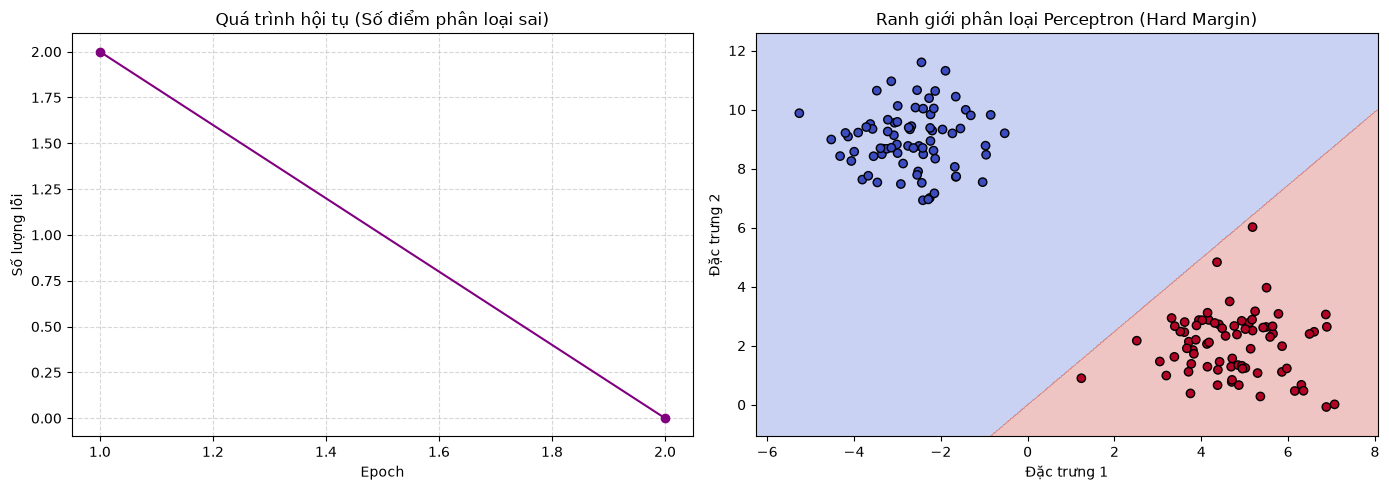

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron as SklearnPerceptron
from sklearn.datasets import make_blobs
from utils.metrics import accuracy_score

# 1. Sinh dữ liệu phân tách tuyến tính HOÀN TOÀN (Bắt buộc với PLA)
X, y = make_blobs(n_samples=150, centers=2, n_features=2, random_state=42, cluster_std=1.05)

# 2. Huấn luyện model Scratch
t0 = time.time()
model_scratch = Perceptron(learning_rate=0.1, epochs=100).fit(X, y)
t_scratch = (time.time() - t0) * 1000

# 3. Huấn luyện model Sklearn
t0 = time.time()
model_sklearn = SklearnPerceptron(eta0=0.1, max_iter=100, random_state=42).fit(X, y)
t_sklearn = (time.time() - t0) * 1000

# 4. Đánh giá
y_pred_scratch = model_scratch.predict(X)
y_pred_sklearn = model_sklearn.predict(X)

print(f"{'Metric':<20} | {'Scratch':<15} | {'Sklearn':<15}")
print("-" * 55)
print(f"{'Accuracy Score':<20} | {accuracy_score(y, y_pred_scratch):<15.4f} | {accuracy_score(y, y_pred_sklearn):<15.4f}")
print(f"{'Epochs to converge':<20} | {len(model_scratch.errors_history):<15} | {'N/A (early stop)':<15}")

# 5. Trực quan hóa quá trình hội tụ và ranh giới
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị 1: Lỗi giảm dần về 0
ax1.plot(range(1, len(model_scratch.errors_history) + 1), model_scratch.errors_history, marker='o', color='purple')
ax1.set_title("Quá trình hội tụ (Số điểm phân loại sai)")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Số lượng lỗi")
ax1.grid(True, linestyle='--', alpha=0.5)

# Đồ thị 2: Decision Boundary (Đường thẳng chia cắt)
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = model_scratch.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

ax2.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
ax2.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
ax2.set_title("Ranh giới phân loại Perceptron (Hard Margin)")
ax2.set_xlabel("Đặc trưng 1")
ax2.set_ylabel("Đặc trưng 2")

plt.tight_layout()
plt.show()